In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import os
import warnings

# Ignore basic warnings for cleaner output
warnings.filterwarnings('ignore')
print("Step 1 Complete: Libraries imported.")

Step 1 Complete: Libraries imported.


In [3]:
# 2. Load raw dataset
# PASTE YOUR COPIED FILE PATH INSIDE THE QUOTES BELOW
file_path = r"C:\Users\siddh\OneDrive\Desktop\BISPEC PAIRWISE - AI\BiSpec-Pairwise-AI\DATA\RAW DATA\lung cancer.xlsx - Results.csv"

if not file_path:
    raise ValueError("Please paste your file path into the file_path variable!")
if not os.path.exists(file_path):
    raise FileNotFoundError(f"Cannot find the file at: {file_path}")

df = pd.read_csv(file_path)
print(f"Step 2 Complete: Dataset loaded successfully from {file_path}")

Step 2 Complete: Dataset loaded successfully from C:\Users\siddh\OneDrive\Desktop\BISPEC PAIRWISE - AI\BiSpec-Pairwise-AI\DATA\RAW DATA\lung cancer.xlsx - Results.csv


In [4]:
# 3. Initial inspection
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- First 5 Rows ---")
display(df.head())

--- Dataset Shape ---
Rows: 791, Columns: 8

--- First 5 Rows ---


,Drug,Target(Gene Name),Target(Gene Symbol),Active Indication(Indication Name),Originator Organization,Drug Highest Phase,Drug Approved Country/Location,Approval Date
0,Elranatamab,BCMA + CD3,"TNFRSF17, CD3E",Relapsed/refractory multiple myeloma | Multipl...,Pfizer Inc.,"Approved, NDA/BLA",US | EU | IS | LI | NO,2023-08-14
1,Talquetamab,CD3 + GPRC5D,"CD3E, GPRC5D",Plasma cell myeloma refractory | Relapse multi...,"Janssen Pharmaceuticals, Inc.","Approved, NDA/BLA",US | EU | IS | LI | NO,2023-08-09
2,Epcoritamab,CD20 + CD3,"MS4A1, CD3E",Mediastinal large B-cell lymphoma | Recurrent ...,Genmab A/S,"Approved, NDA/BLA",US | EU | JP | IS | LI | NO,2023-05-19
3,Glofitamab,CD20 + CD3,"MS4A1, CD3E",Diffuse large B-cell lymphoma recurrent | Diff...,F. Hoffmann-La Roche Ltd.,"Approved, NDA/BLA",US | CN | EU | CA | IS | LI | NO,2023-03-25
4,Teclistamab,BCMA + CD3,"TNFRSF17, CD3E",Multiple Myeloma | Relapse multiple myeloma | ...,Janssen Research & Development LLC,"Approved, NDA/BLA",US | EU | IS | LI | NO,2022-08-23


In [5]:
# 4. Check missing values
print("--- Missing Values per Column ---")
missing_values = df.isnull().sum()
print(missing_values)

# Calculate percentage of missing data
missing_percent = (missing_values / len(df)) * 100
print("\n--- Missing Values Percentage ---")
print(missing_percent.round(2).astype(str) + '%')

--- Missing Values per Column ---
Drug                                  0
Target(Gene Name)                     0
Target(Gene Symbol)                   0
Active Indication(Indication Name)    0
Originator Organization               0
Drug Highest Phase                    0
Drug Approved Country/Location        0
Approval Date                         0
dtype: int64

--- Missing Values Percentage ---
Drug                                  0.0%
Target(Gene Name)                     0.0%
Target(Gene Symbol)                   0.0%
Active Indication(Indication Name)    0.0%
Originator Organization               0.0%
Drug Highest Phase                    0.0%
Drug Approved Country/Location        0.0%
Approval Date                         0.0%
dtype: str


In [6]:
# 5. Check duplicates
duplicate_count = df.duplicated().sum()
print(f"--- Duplicate Rows Found: {duplicate_count} ---")

if duplicate_count > 0:
    print("Preview of duplicated rows:")
    display(df[df.duplicated(keep=False)].head())

--- Duplicate Rows Found: 0 ---


In [7]:
# 6. Check data types
print("--- Data Types ---")
print(df.dtypes)

--- Data Types ---
Drug                                  str
Target(Gene Name)                     str
Target(Gene Symbol)                   str
Active Indication(Indication Name)    str
Originator Organization               str
Drug Highest Phase                    str
Drug Approved Country/Location        str
Approval Date                         str
dtype: object


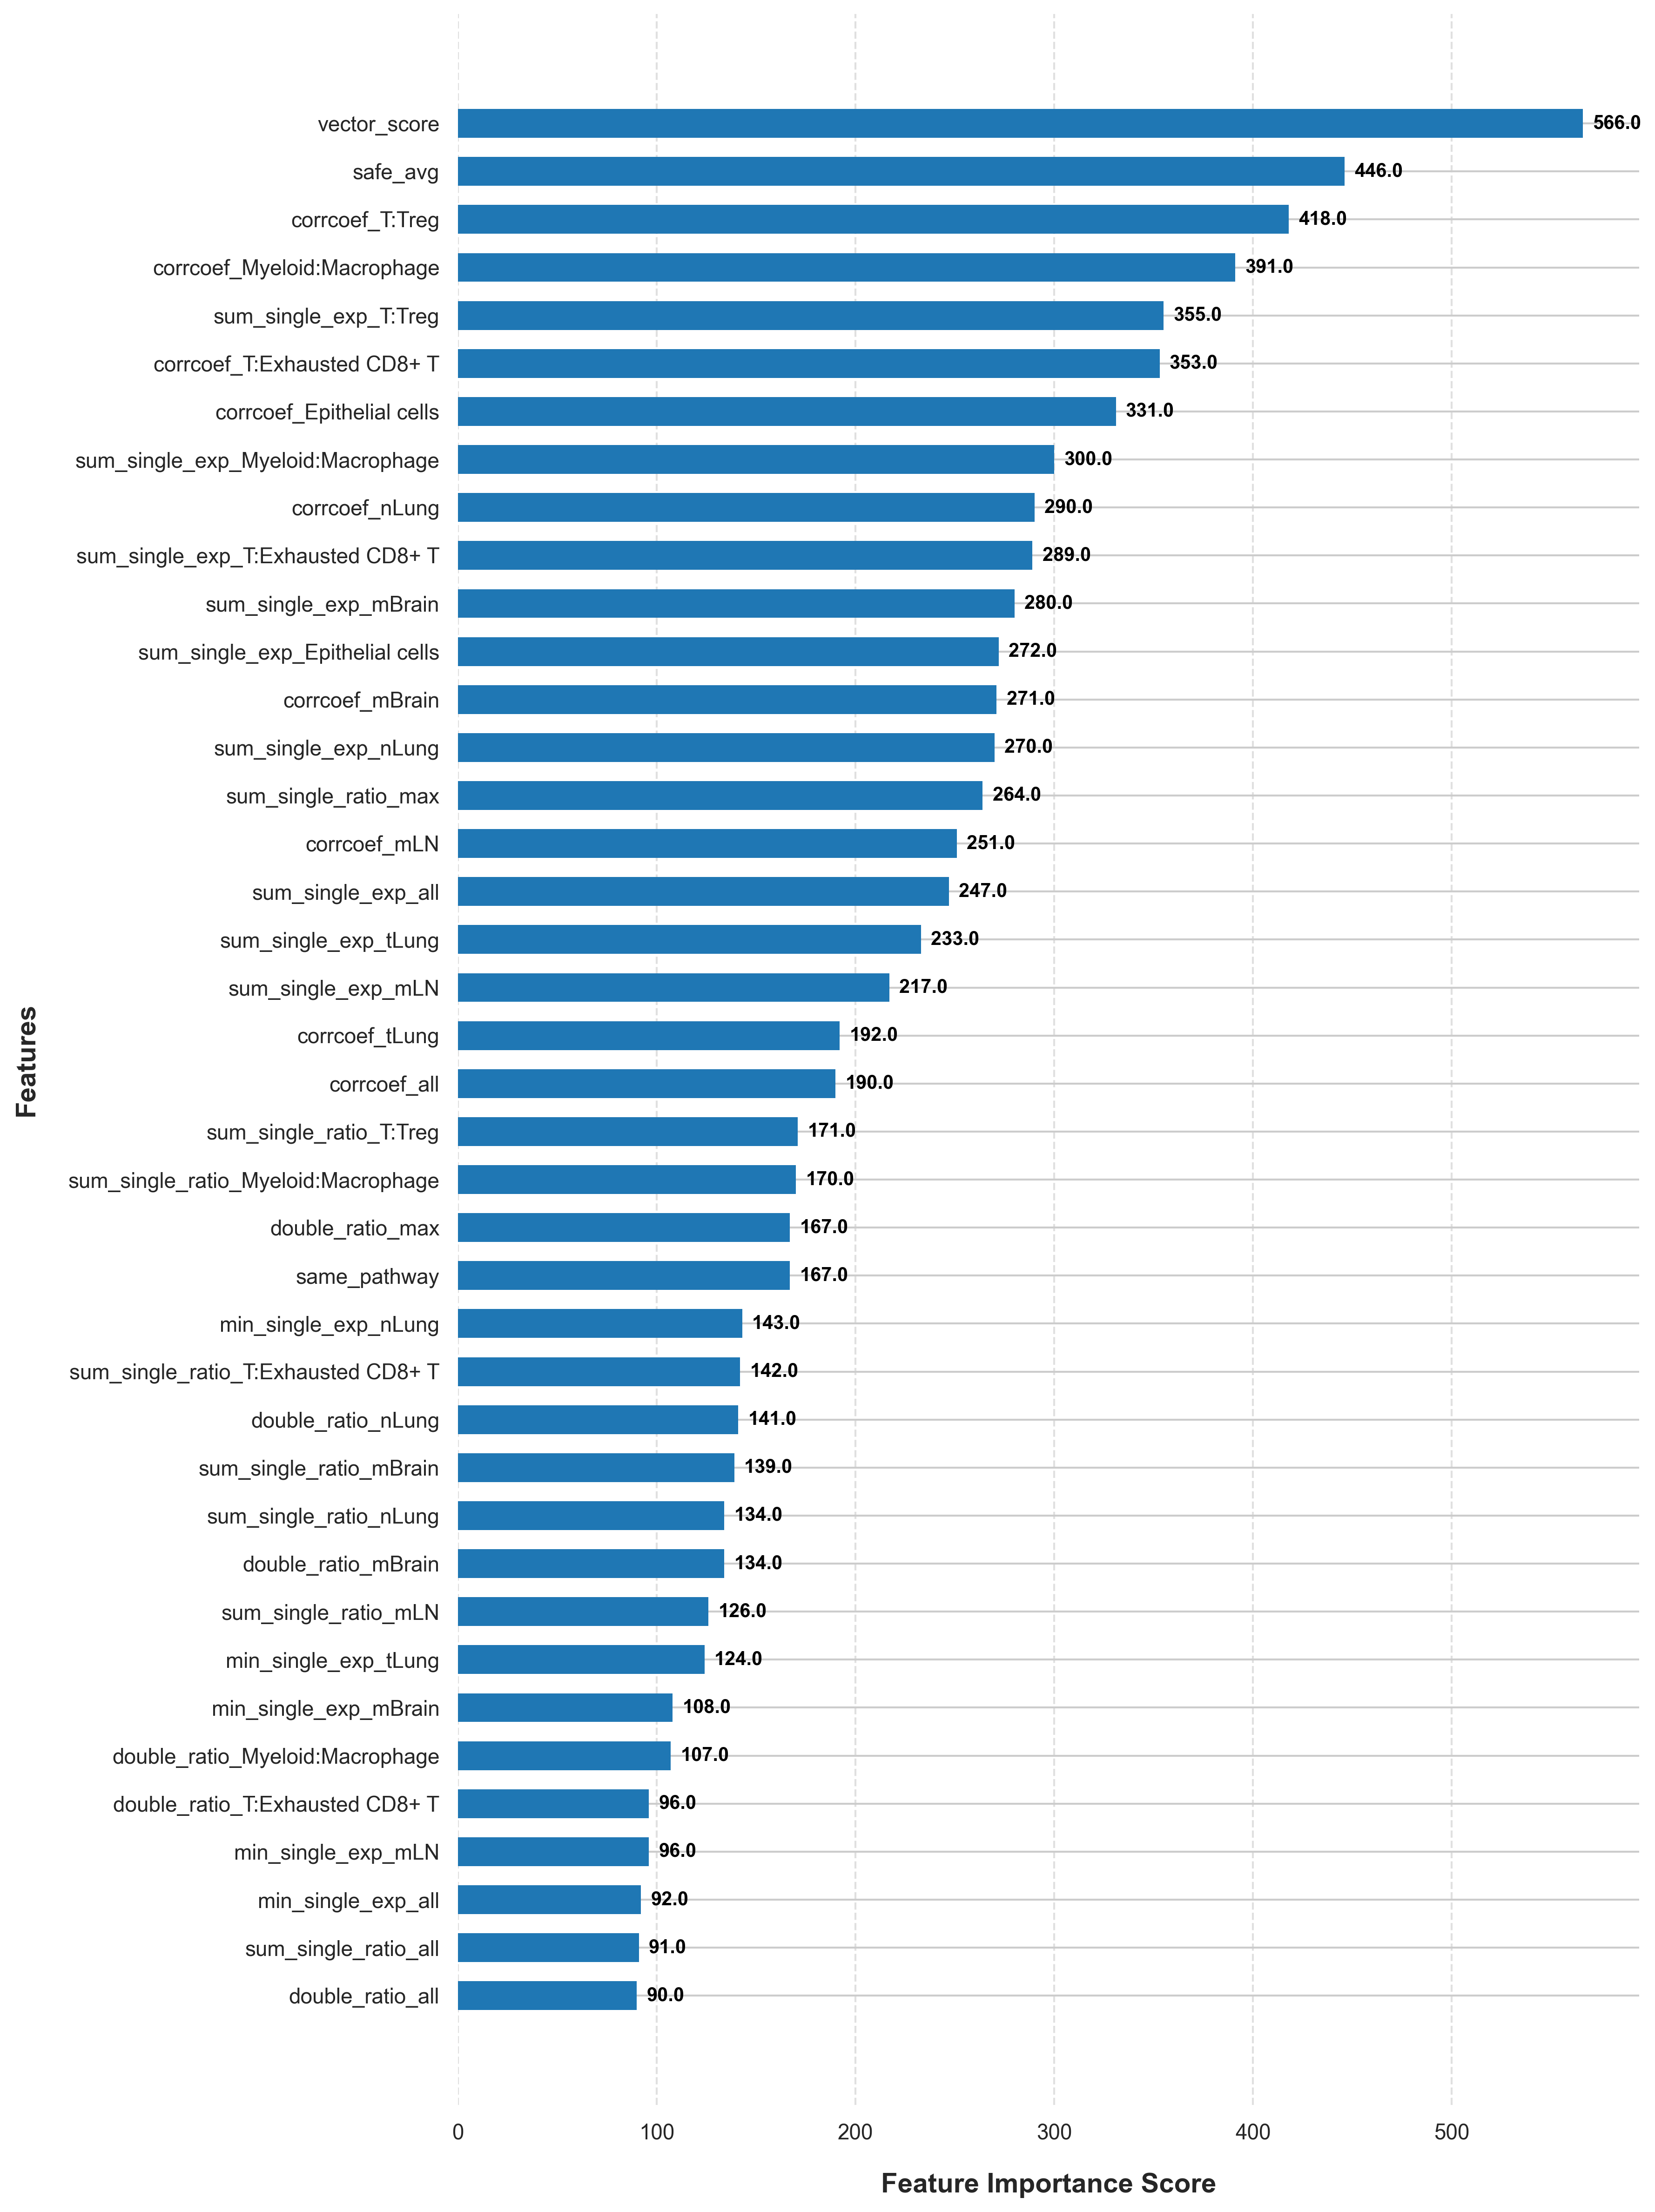

Success! High-resolution slide asset saved as: PPT_Complete_Feature_Importance.png


In [1]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extracting ALL 40 Features from the original chart
data = {
    'Features': [
        'vector_score', 'safe_avg', 'corrcoef_T:Treg', 'corrcoef_Myeloid:Macrophage', 
        'sum_single_exp_T:Treg', 'corrcoef_T:Exhausted CD8+ T', 'corrcoef_Epithelial cells',
        'sum_single_exp_Myeloid:Macrophage', 'corrcoef_nLung', 'sum_single_exp_T:Exhausted CD8+ T', 
        'sum_single_exp_mBrain', 'sum_single_exp_Epithelial cells', 'corrcoef_mBrain', 
        'sum_single_exp_nLung', 'sum_single_ratio_max', 'corrcoef_mLN', 
        'sum_single_exp_all', 'sum_single_exp_tLung', 'sum_single_exp_mLN', 
        'corrcoef_tLung', 'corrcoef_all', 'sum_single_ratio_T:Treg', 
        'sum_single_ratio_Myeloid:Macrophage', 'same_pathway', 'double_ratio_max', 
        'min_single_exp_nLung', 'sum_single_ratio_T:Exhausted CD8+ T', 'double_ratio_nLung', 
        'sum_single_ratio_mBrain', 'double_ratio_mBrain', 'sum_single_ratio_nLung', 
        'sum_single_ratio_mLN', 'min_single_exp_tLung', 'min_single_exp_mBrain', 
        'double_ratio_Myeloid:Macrophage', 'min_single_exp_mLN', 'double_ratio_T:Exhausted CD8+ T', 
        'min_single_exp_all', 'sum_single_ratio_all', 'double_ratio_all'
    ],
    'Importance Score': [
        566.0, 446.0, 418.0, 391.0, 355.0, 353.0, 331.0, 
        300.0, 290.0, 289.0, 280.0, 272.0, 271.0, 270.0, 
        264.0, 251.0, 247.0, 233.0, 217.0, 192.0, 190.0, 
        171.0, 170.0, 167.0, 167.0, 143.0, 142.0, 141.0, 
        139.0, 134.0, 134.0, 126.0, 124.0, 108.0, 107.0, 
        96.0, 96.0, 92.0, 91.0, 90.0
    ]
}

df_importance = pd.DataFrame(data)

# Sort values so the highest is at the top of the bar chart
df_importance = df_importance.sort_values(by='Importance Score', ascending=True)

# 2. Set up the visual style for PowerPoint
sns.set_theme(style="whitegrid")
# Increased height to 16 to accommodate all 40 features without squishing
plt.figure(figsize=(12, 16), dpi=300) 

# Create the bar chart with the original blue color scheme
bars = plt.barh(df_importance['Features'], df_importance['Importance Score'], 
                color='#1f77b4', height=0.6, edgecolor='none')

# 3. Customize labels and titles for readability
plt.xlabel('Feature Importance Score', fontsize=14, fontweight='bold', labelpad=15)
plt.ylabel('Features', fontsize=14, fontweight='bold', labelpad=15)

# Increase tick font sizes
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# 4. Add the exact score values directly onto the bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5,  bar.get_y() + bar.get_height()/2, f'{width:.1f}', va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 5. Clean up the borders
sns.despine(left=True, bottom=True)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Save the image directly to your folder
output_file = "PPT_Complete_Feature_Importance.png"
plt.tight_layout()
plt.savefig(output_file, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

print(f"Success! High-resolution slide asset saved as: {output_file}")

